# Identity: usuário, M2M e OBO

30 minutos

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

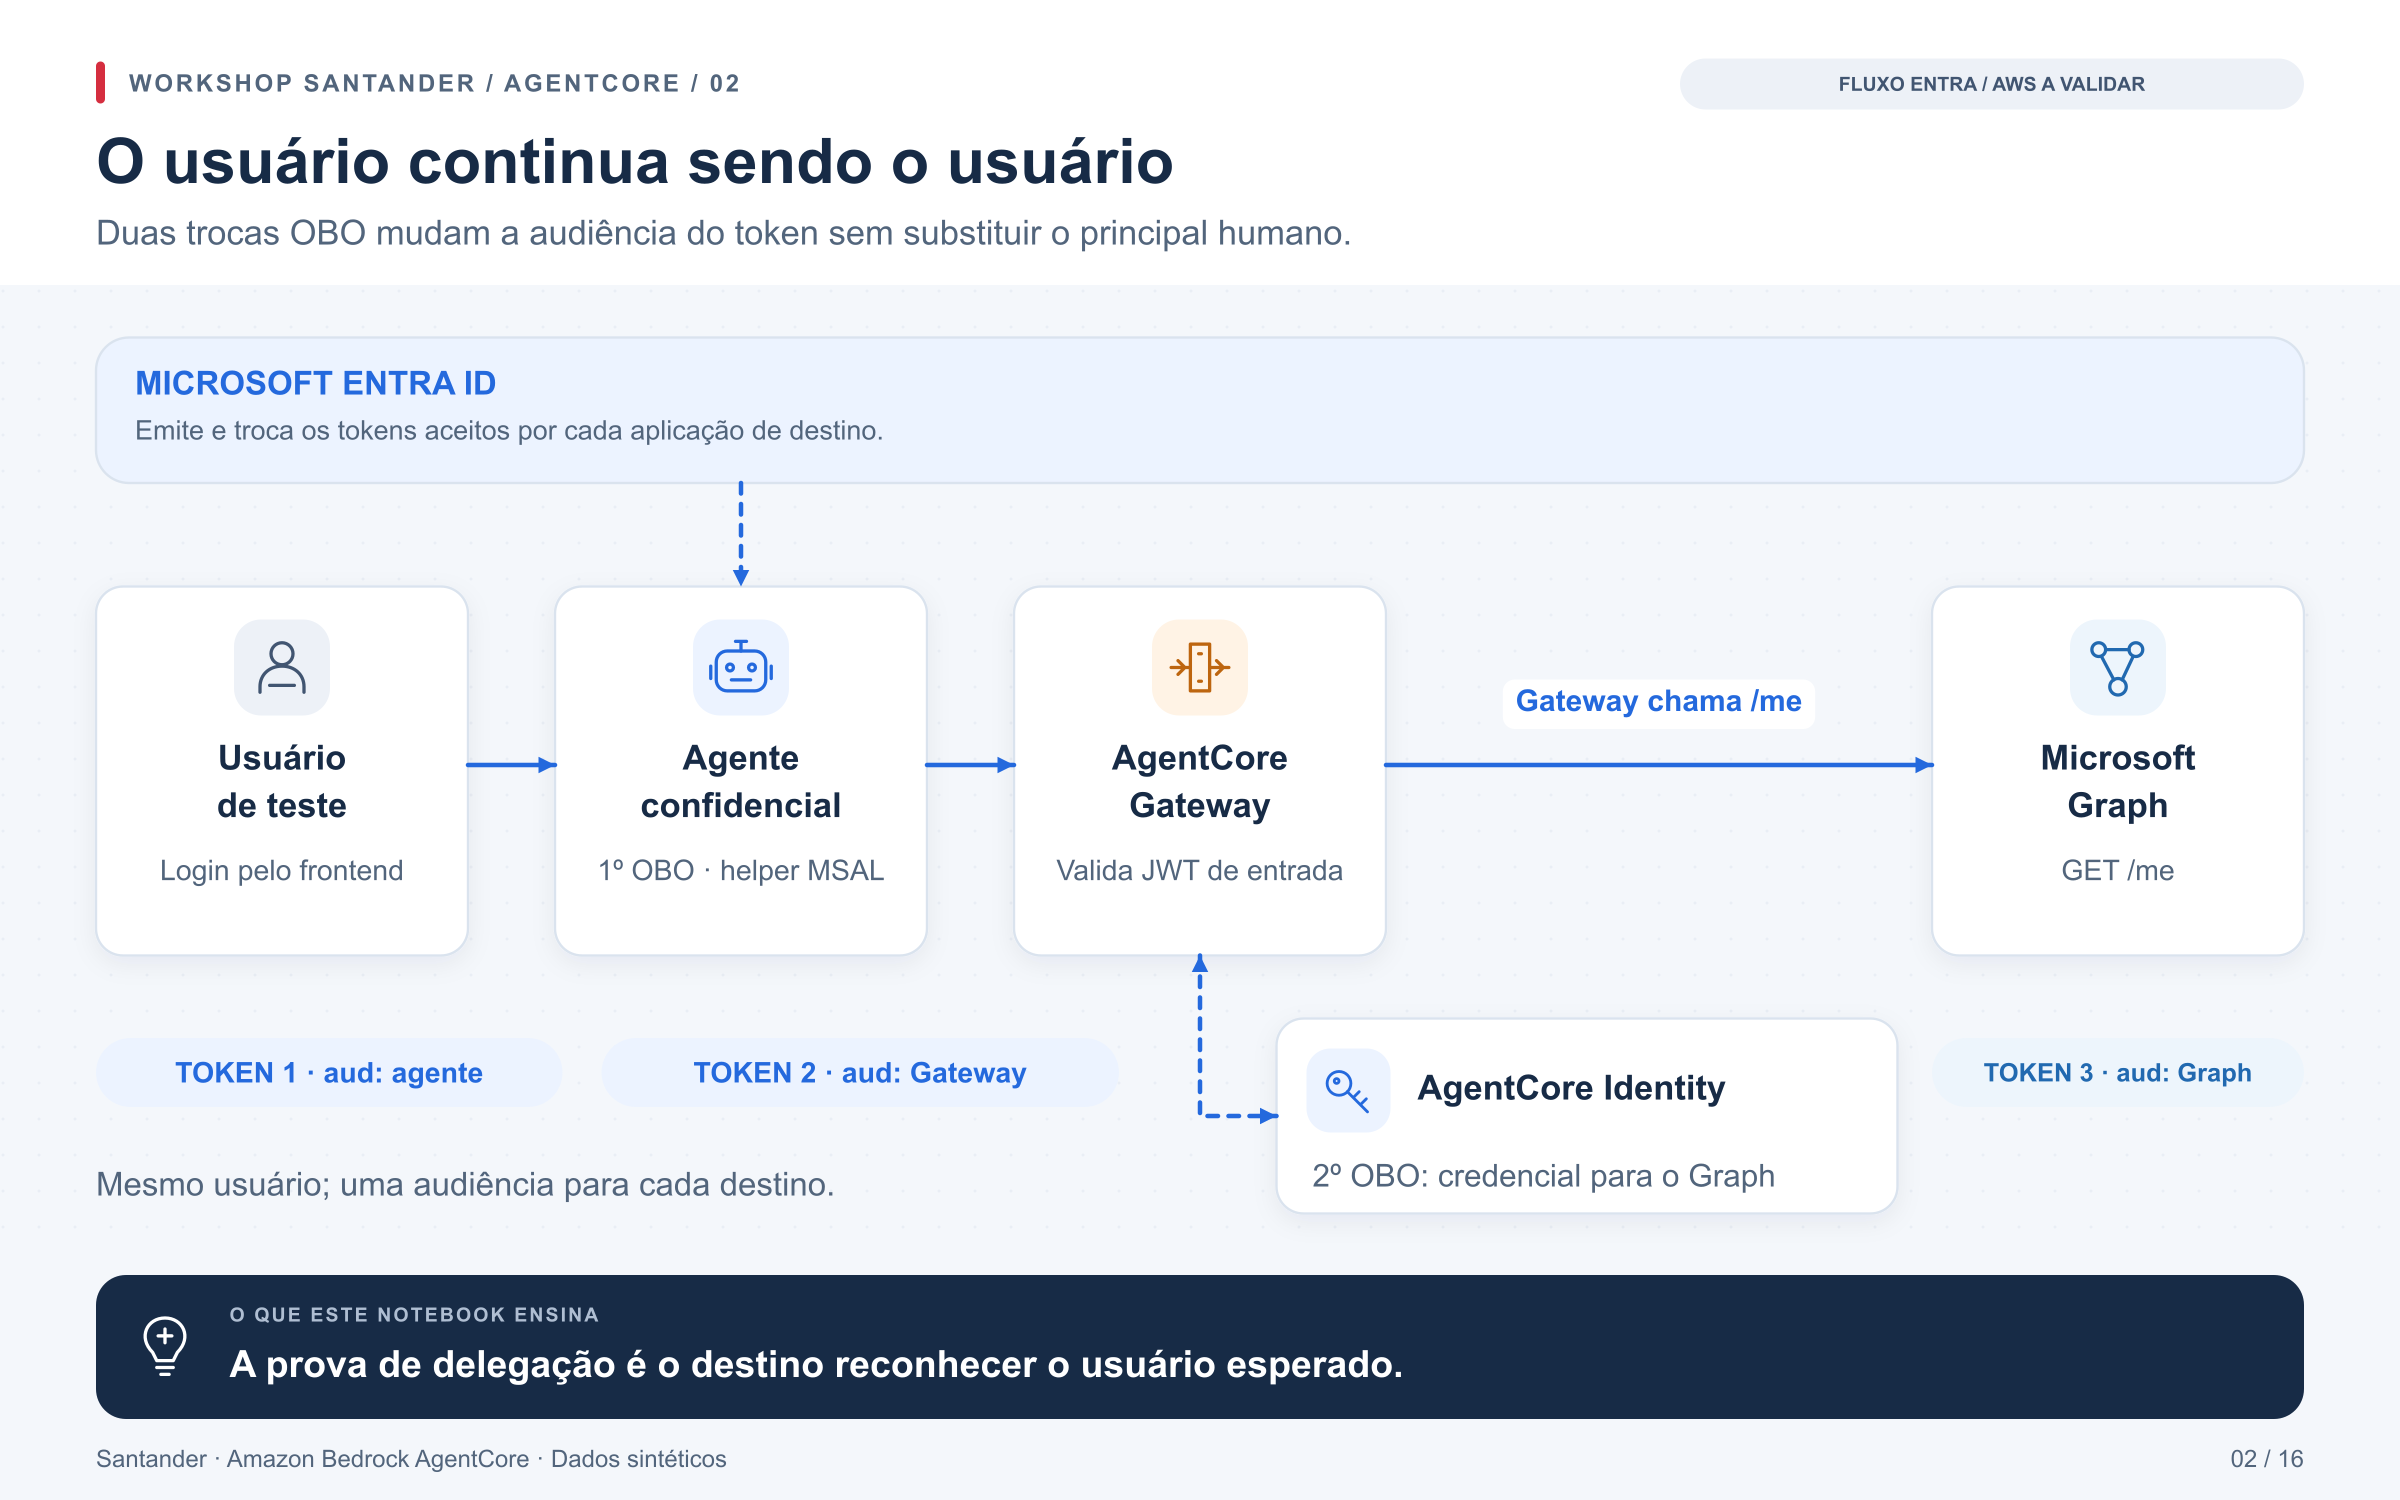

**Objetivo visual:** Comparar o ID devolvido por Graph /me com o OID esperado de dois usuários de teste.

[Abrir PNG](../docs/diagramas/png/02_identity_entra_obo.png) · [SVG editável](../docs/diagramas/svg/02_identity_entra_obo.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 3 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Gateway e ferramentas](01_gateway_targets.ipynb) · [Próximo: Identidade do agente](03_identity_agente_mcp.ipynb)

## Conceitos para acompanhar este laboratório

**JWT** é um formato de token com claims, isto é, informações assinadas.
`iss` identifica o emissor, `aud` a API destinatária e `exp` a expiração.
**JWKS** publica as chaves usadas para verificar a assinatura; simplesmente
decodificar o token não valida sua autenticidade.

**M2M**, com `client_credentials`, representa uma aplicação. **OBO
(on-behalf-of)** permite que uma aplicação obtenha um novo token delegado
para outra API em nome do usuário. O token original não deve ser reutilizado
numa API de audiência diferente. O fluxo exige configuração e consentimentos
no provedor de identidade (**IdP**).

No Entra, `tid` + `oid` identifica o usuário no tenant; `azp`/`appid`
identifica a aplicação chamadora. Confira a verificação em
[identity.py](../src/santander_demo/identity.py) e a comparação com Graph
em `CloudWorkshop.graph_me()` de [cloud.py](../src/santander_demo/cloud.py).

**Documentação oficial para aprofundar:**

* [Microsoft: fluxo OBO](https://learn.microsoft.com/pt-br/entra/identity-platform/v2-oauth2-on-behalf-of-flow)
* [Microsoft: claims de access tokens](https://learn.microsoft.com/pt-br/entra/identity-platform/access-token-claims-reference)
* [AgentCore Identity: troca OBO](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/on-behalf-of-token-exchange.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

No cenário principal, o Gateway valida o token para sua API e o Identity troca
essa credencial pelo token delegado do Microsoft Graph. A única operação Graph
exposta é `/me`; não há leitura de emails ou escrita.

M2M autentica a aplicação. USER_FEDERATION envolve login/consentimento ao recurso.
OBO usa uma asserção do usuário que já chegou à aplicação. São fluxos distintos.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

### Obter e verificar a identidade usada nas chamadas

Vamos preparar a variável `token` para as próximas chamadas. No modo local,
o emissor do laboratório criará um JWT de teste para o usuário `ambos`,
habilitado aos cenários de Riscos e Fraude, e verificará sua validade.

No modo AWS, a célula solicitará um token Entra já obtido para a audiência
do Gateway, com entrada oculta por `getpass`, e o validará antes de continuar.
A saída será um resumo da identidade verificada; o token ficará em memória
e não será impresso. Esta etapa prepara a autenticação, mas ainda não executa
uma ferramenta nem demonstra uma troca OBO.

In [ ]:
if MODE == "aws":
    from getpass import getpass
    # Ou use login_confidential_agent(config), que obtém o token via OBO do agente.
    token = getpass("Token Entra de teste para a audiência do Gateway: ")
    identity = cloud.verify_token(token)
    print(identity.summary())
else:
    token = lab.idp.token("ambos")
    print(lab.idp.verifier.verify(token).summary())

### Verificar a audiência e a identidade no destino

No modo AWS, vamos consultar `/me` do Microsoft Graph pelo fluxo
configurado no Gateway. O helper comparará o OID do usuário do token
e o ID devolvido pelo Graph com `expected_graph_oid`; esperamos
`graph_user_matches: True`.

No modo local, faremos um teste negativo: tentaremos validar o token
da origem com um verificador que exige a audiência `graph`.
Esperamos `AUTH_INVALID_TOKEN`, comprovando a separação entre
audiências. Nesse ramo, Entra OBO e Graph continuarão como `NOT_RUN`.

In [ ]:
if MODE == "aws":
    proof = await cloud.graph_me(token)
    assert proof["graph_user_matches"]
    print(proof)
else:
    from santander_demo.identity import JwtVerifier
    wrong_audience = JwtVerifier(key=lab.idp._key.public_key(),
        issuer=lab.idp.issuer, tenant=lab.idp.tenant, audience="graph")
    try:
        wrong_audience.verify(token)
        raise AssertionError("Token da origem aceito no destino!")
    except DemoError as exc:
        assert exc.code == "AUTH_INVALID_TOKEN"
    print({"audience_boundary": "PASS", "entra_obo": "NOT_RUN",
           "graph_me": "NOT_RUN"})

**Prova AWS:** execute com usuário A, ajuste `expected_graph_oid` ao OID desse
usuário e repita com B. A asserção compara IDs exatos, não formato de email.
`azp` (v2) ou `appid` (v1) identifica o cliente que obteve o token; `tid+oid`
identifica o principal humano nesse tenant.

O modo local não emula uma troca OBO bem-sucedida. Registre Entra/Graph como
não executados até observar as duas identidades reais.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'cloud', 'config', 'identity', 'lab', 'proof', 'token',
 'wrong_audience']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json